In [40]:
%pip install yfinance
%pip install matplotlib
%pip install sqlite as sq3
%pip install numpy
%pip install pandas

##Install the packages and libraries used in this module


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
ERROR: Could not find a version that satisfies the requirement sqlite (from versions: none)

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
ERROR: No matching distribution found for sqlite
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the k

In [1]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
import datetime
from numpy import random
import seaborn as sns
##Import pandas, yfinance, numpy and matplotlib from the downloaded libraries

In [2]:
hyundai=pd.read_csv('Hyundai_Stocks.csv',skiprows=1) #Ignore the first row
#From the downloaded excel csv file with history of Hyundai Stocks, simply import it and use pandas to read is

In [41]:
import os

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

Current folder: /Users/jake.l/Desktop/python-test/Analysis
Files: ['Hyundai_Dataset.numbers', 'Sales_Analysis.ipynb', 'Jake_Lee_Resume_Lifespace_Group.pdf', 'Hyundai_Analysis.ipynb', 'simulations.csv', 'Walmart_Dataset.numbers', 'Hyundai Motor Stock Price History (1).xlsx', 'Walmart_Dataset.csv', 'Hyundai Motor Stock Price History .csv', 'Hyundai_Stocks.numbers', 'Hyundai_Stocks.csv', 'Numpy.py', 'Numpy_Rev', 'Hyundai_Analysis_DCF.ipynb', 'Hyundai_Analysis_Images.docx', 'Hyundai_DCF_Analysis.xlsx', 'Numpy_TUT.ipynb', 'Hyundai_Analysis_Images.pdf', 'Hyundai_Share_Prices.csv']


In [42]:
hyundai

,Date,Price,Open,High,Low,Vol.,Change %
0,Date,Price,Open,High,Low,Vol.,Change %
1,8/25/2026,"421,000","422,000","427,250","406,000",570.22K,1.69%
2,8/24/2026,"414,000","416,000","420,000","408,000",349.74K,-0.24%
3,8/21/2026,"415,000","406,500","420,500","405,000",371.71K,-0.60%
4,8/20/2026,"417,500","417,000","425,000","408,000",421.24K,0.85%
...,...,...,...,...,...,...,...
2088,2/1/2019,"129,500","129,500","130,000","128,500",391.59K,0.00%
2089,1/31/2019,"129,500","130,000","131,000","128,500",509.45K,0.00%
2090,1/30/2019,"129,500","128,500","129,500","126,500",404.00K,1.17%
2091,1/29/2019,"128,000","126,500","128,500","126,000",445.08K,1.19%


In [43]:
hyundai.columns=hyundai.iloc[0]
#Removes any unnecessary column headers

In [44]:
hyundai2=hyundai.iloc[1:]
hyundai2['Date'] = pd.to_datetime(hyundai2['Date'])

hyundai_data = hyundai2.set_index('Date')

In [45]:
hyundai2.dtypes

0
Date        datetime64[us]
Price                  str
Open                   str
High                   str
Low                    str
Vol.                   str
Change %               str
dtype: object

In [46]:
hyundai_data=hyundai2.set_index('Date')
#Set the index to Date


In [47]:
hyundai_data=hyundai_data.rename(columns={'Price':'Price_KRWon'}) 
#Change the column name from Price --> Price_KRWon for clarity

In [48]:
hyundai_data.dtypes
#Currently, the datas are set all in objects

0
Price_KRWon    str
Open           str
High           str
Low            str
Vol.           str
Change %       str
dtype: object

In [49]:
hyundai_data['Price_KRWon'].convert_dtypes(float)

Date
2026-08-25    421,000
2026-08-24    414,000
2026-08-21    415,000
2026-08-20    417,500
2026-08-19    414,000
               ...   
2019-02-01    129,500
2019-01-31    129,500
2019-01-30    129,500
2019-01-29    128,000
2019-01-28    126,500
Name: Price_KRWon, Length: 2092, dtype: string

In [50]:
hyundai_data['Price_KRWon']
hyundai_data.dtypes

0
Price_KRWon    str
Open           str
High           str
Low            str
Vol.           str
Change %       str
dtype: object

In [51]:
hyundai_datas=hyundai_data.copy()

In [52]:
hyundai_datas=hyundai_datas.replace(',','',regex=True) #Finds a pattern of ',' and replaces it with ''. This is done so that when converting into float64, the commas don't interfere with the conversion

In [53]:
hyundai_datas['Change %']=hyundai_datas['Change %'].replace('%','',regex=True) #Finds a pattern of '%' and replaces it with ''. This is done so that when converting into float64, the % don't interfere with the conversion

In [54]:
hdata=hyundai_datas.iloc[:,[0,1,2,3,5]] #Exclude Volume column cause it is irrelevant

In [55]:
hdata=hdata.astype(float)
hdata.dtypes

0
Price_KRWon    float64
Open           float64
High           float64
Low            float64
Change %       float64
dtype: object

In [56]:
hdata
hdata['Price_AUD']=hdata['Price_KRWon']/990.03 #Exchange Rate from KR Won to AUD. Exchange Rate has been taken from https://www.rba.gov.au/statistics/frequency/exchange-rates.html, RBA, used 28/08/2026 exchange rates. (Potentially change so exchange rates are updated live?)

In [57]:
hdata

,Price_KRWon,Open,High,Low,Change %,Price_AUD
Date,,,,,,
2026-08-25,421000.0,422000.0,427250.0,406000.0,1.69,425.239639
2026-08-24,414000.0,416000.0,420000.0,408000.0,-0.24,418.169146
2026-08-21,415000.0,406500.0,420500.0,405000.0,-0.60,419.179217
2026-08-20,417500.0,417000.0,425000.0,408000.0,0.85,421.704393
2026-08-19,414000.0,416000.0,422500.0,406500.0,-4.83,418.169146
...,...,...,...,...,...,...
2019-02-01,129500.0,129500.0,130000.0,128500.0,0.00,130.804117
2019-01-31,129500.0,130000.0,131000.0,128500.0,0.00,130.804117
2019-01-30,129500.0,128500.0,129500.0,126500.0,1.17,130.804117


In [58]:
hprice=hdata.Price_AUD #Now, we will be using this AUD Prices to commence the Monte-Carlo Simulation
hprice

Date
2026-08-25    425.239639
2026-08-24    418.169146
2026-08-21    419.179217
2026-08-20    421.704393
2026-08-19    418.169146
                 ...    
2019-02-01    130.804117
2019-01-31    130.804117
2019-01-30    130.804117
2019-01-29    129.289011
2019-01-28    127.773906
Name: Price_AUD, Length: 2092, dtype: float64

In [59]:
hprices=hprice.pct_change()
hprices

Date
2026-08-25         NaN
2026-08-24   -0.016627
2026-08-21    0.002415
2026-08-20    0.006024
2026-08-19   -0.008383
                ...   
2019-02-01    0.027778
2019-01-31    0.000000
2019-01-30    0.000000
2019-01-29   -0.011583
2019-01-28   -0.011719
Name: Price_AUD, Length: 2092, dtype: float64

In [60]:
AUD_Hyundai=pd.DataFrame([hprice,hprices]).T #Compute the %Changes as well
AUD_Hyundai.rename(columns={4: '%_Change'})

,Price_AUD,Price_AUD
Date,,
2026-08-25,425.239639,NaN
2026-08-24,418.169146,-0.016627
2026-08-21,419.179217,0.002415
2026-08-20,421.704393,0.006024
2026-08-19,418.169146,-0.008383
...,...,...
2019-02-01,130.804117,0.027778
2019-01-31,130.804117,0.000000
2019-01-30,130.804117,0.000000


In [61]:
AUD_Hyundai.columns=['Price_AUD','Percent_AUD']

In [62]:
AUD_Hyundai.dropna(inplace=True)

In [63]:
AUD_Hyundai['Cumfactor']=AUD_Hyundai.Percent_AUD+1


In [64]:
AUD_Hyundai=AUD_Hyundai.reset_index()

In [65]:
AUD_Hyundai['Date']=pd.to_datetime(AUD_Hyundai['Date'])

In [66]:
AUD_Hyundai.set_index('Date')

,Price_AUD,Percent_AUD,Cumfactor
Date,,,
2026-08-24,418.169146,-0.016627,0.983373
2026-08-21,419.179217,0.002415,1.002415
2026-08-20,421.704393,0.006024,1.006024
2026-08-19,418.169146,-0.008383,0.991617
2026-08-18,439.380625,0.050725,1.050725
...,...,...,...
2019-02-01,130.804117,0.027778,1.027778
2019-01-31,130.804117,0.000000,1.000000
2019-01-30,130.804117,0.000000,1.000000


In [67]:
#AUD_Hyundai=AUD_Hyundai.set_index('Date') #Date was set in Object DataType so convert it into DateTime to sort it accordingly
AUD_Hyundai['Date'].sort_index(ascending=True)
AUD_Hyundai['Logarithmic_Changes_Daily']=np.log((AUD_Hyundai.Price_AUD/AUD_Hyundai['Price_AUD'].shift(1))) #Logarithmic changes can be estimated roughly up to +-5% changes. https://people.duke.edu/~rnau/411log.htm
AUD_Hyundai=AUD_Hyundai.sort_index(ascending=False)
simulation=AUD_Hyundai.copy()
simulation.dropna(inplace=True)
simulation=simulation.set_index('Date')
simulation

,Price_AUD,Percent_AUD,Cumfactor,Logarithmic_Changes_Daily
Date,,,,
2019-01-28,127.773906,-0.011719,0.988281,-0.011788
2019-01-29,129.289011,-0.011583,0.988417,-0.011651
2019-01-30,130.804117,0.000000,1.000000,0.000000
2019-01-31,130.804117,0.000000,1.000000,0.000000
2019-02-01,130.804117,0.027778,1.027778,0.027399
...,...,...,...,...
2026-08-14,457.561892,0.041379,1.041379,0.040546
2026-08-18,439.380625,0.050725,1.050725,0.049480
2026-08-19,418.169146,-0.008383,0.991617,-0.008419


In [68]:
simulations=simulation.iloc[:]
simulations=simulations.sort_index(ascending=True)
simulations

,Price_AUD,Percent_AUD,Cumfactor,Logarithmic_Changes_Daily
Date,,,,
2019-01-28,127.773906,-0.011719,0.988281,-0.011788
2019-01-29,129.289011,-0.011583,0.988417,-0.011651
2019-01-30,130.804117,0.000000,1.000000,0.000000
2019-01-31,130.804117,0.000000,1.000000,0.000000
2019-02-01,130.804117,0.027778,1.027778,0.027399
...,...,...,...,...
2026-08-14,457.561892,0.041379,1.041379,0.040546
2026-08-18,439.380625,0.050725,1.050725,0.049480
2026-08-19,418.169146,-0.008383,0.991617,-0.008419


<Axes: xlabel='Date'>

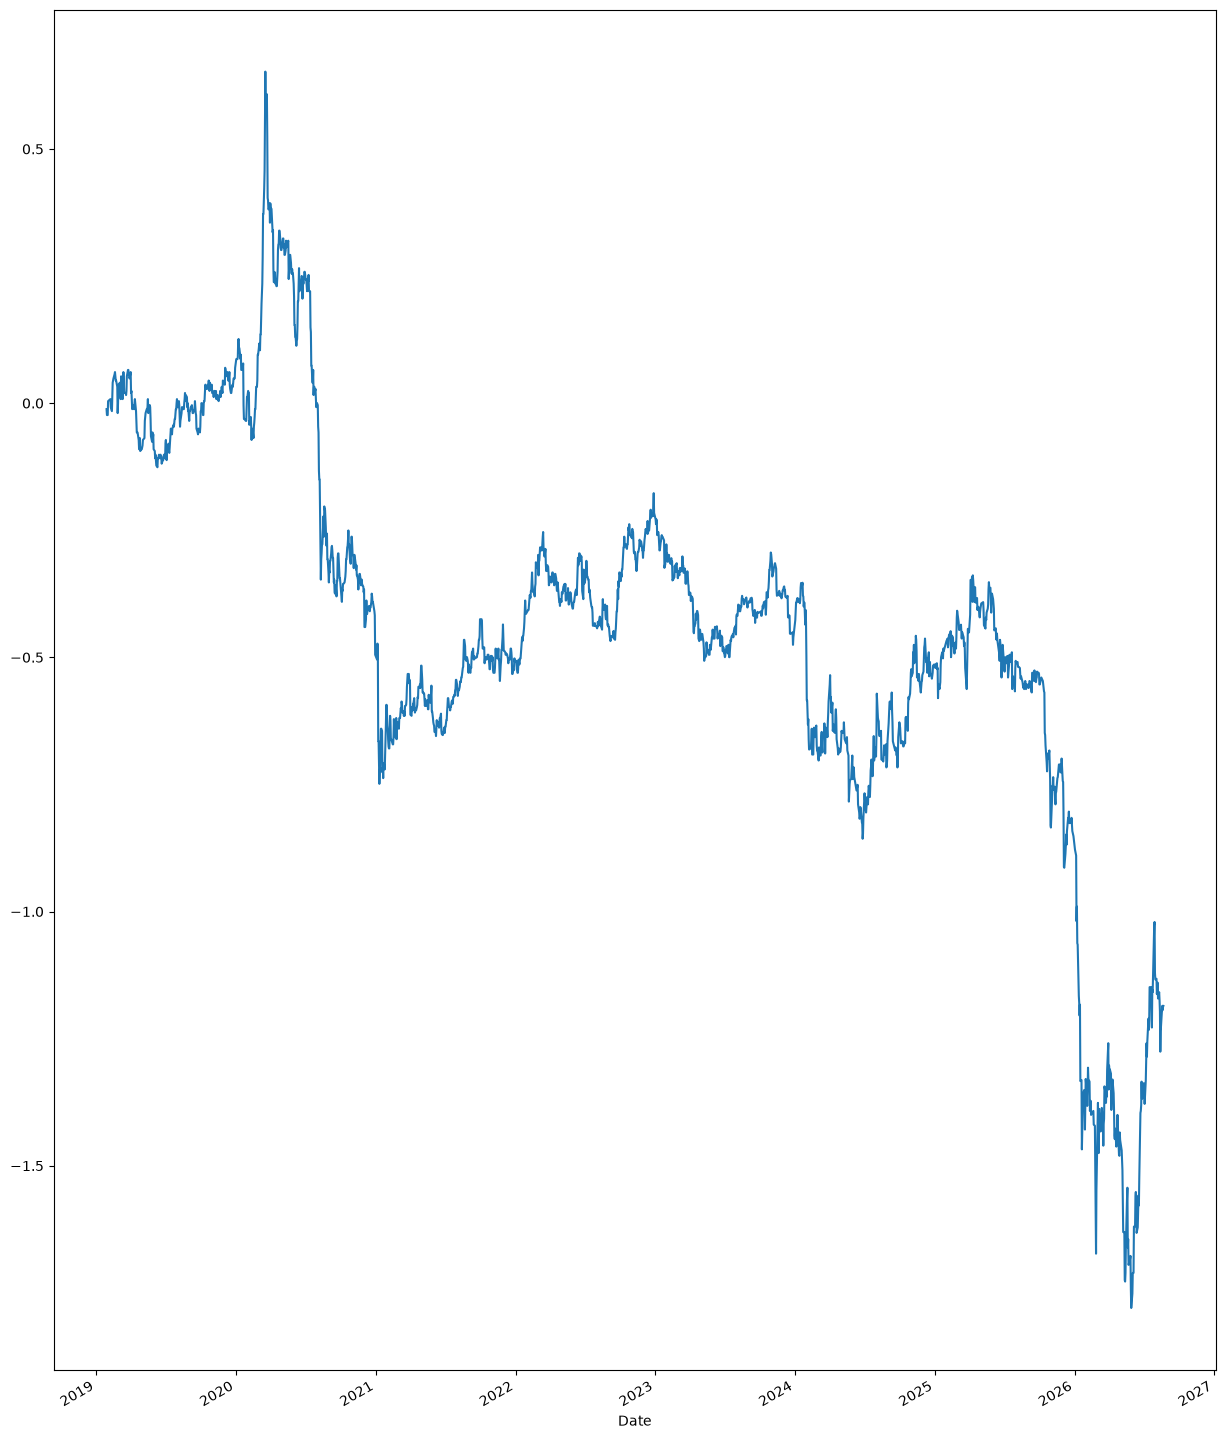

In [69]:
simulations.Logarithmic_Changes_Daily.cumsum().plot(figsize=(15,20),xlabel='Date')

In [70]:
# Running the Monte Carlo Simulation
live_days=252
ann_simulation_mean=simulations.Logarithmic_Changes_Daily.mean() *live_days #Multiply by live days because it is 'daily' and you want annual mean
ann_simulation_mean
ann_simulation_stdev=simulations.Logarithmic_Changes_Daily.std()*np.sqrt(live_days)
datas=[ann_simulation_mean,ann_simulation_stdev]
reps=500
simulator=np.random.normal(ann_simulation_mean/live_days,ann_simulation_stdev/np.sqrt(live_days),(live_days,reps)) #Generates values of normal distributions with [mean = simulation_mean, stdev = simulation_stdev]
simulator

array([[ 0.07721128, -0.00769877, -0.01174078, ..., -0.00165588,
        -0.01953557, -0.01809612],
       [ 0.03919977, -0.00669832, -0.00094836, ...,  0.04245654,
         0.01058327, -0.01838007],
       [-0.01893267,  0.02173692, -0.03010621, ..., -0.00627536,
        -0.00364463,  0.02127927],
       ...,
       [-0.00850562, -0.01689385, -0.04704192, ...,  0.0406314 ,
        -0.00194448, -0.00425584],
       [-0.00891943, -0.00648919, -0.03481721, ...,  0.01199776,
        -0.04053534, -0.02177583],
       [-0.01438158,  0.02123504, -0.0081675 , ...,  0.02158267,
         0.0316542 ,  0.01632141]], shape=(252, 500))

In [71]:
simulations

,Price_AUD,Percent_AUD,Cumfactor,Logarithmic_Changes_Daily
Date,,,,
2019-01-28,127.773906,-0.011719,0.988281,-0.011788
2019-01-29,129.289011,-0.011583,0.988417,-0.011651
2019-01-30,130.804117,0.000000,1.000000,0.000000
2019-01-31,130.804117,0.000000,1.000000,0.000000
2019-02-01,130.804117,0.027778,1.027778,0.027399
...,...,...,...,...
2026-08-14,457.561892,0.041379,1.041379,0.040546
2026-08-18,439.380625,0.050725,1.050725,0.049480
2026-08-19,418.169146,-0.008383,0.991617,-0.008419


In [72]:
wacc = 0.0738

reference_date = simulations.index.min()

simulations['Years'] = (
    simulations.index - reference_date
).days / 365.25

simulations['Present_Value'] = (
    simulations['Price_AUD'] /
    (1 + wacc) ** simulations['Years']
) #Calculates Value of Shares back to Present value

simulations

,Price_AUD,Percent_AUD,Cumfactor,Logarithmic_Changes_Daily,Years,Present_Value
Date,,,,,,
2019-01-28,127.773906,-0.011719,0.988281,-0.011788,0.000000,127.773906
2019-01-29,129.289011,-0.011583,0.988417,-0.011651,0.002738,129.263810
2019-01-30,130.804117,0.000000,1.000000,0.000000,0.005476,130.753128
2019-01-31,130.804117,0.000000,1.000000,0.000000,0.008214,130.727640
2019-02-01,130.804117,0.027778,1.027778,0.027399,0.010951,130.702158
...,...,...,...,...,...,...
2026-08-14,457.561892,0.041379,1.041379,0.040546,7.542779,267.424677
2026-08-18,439.380625,0.050725,1.050725,0.049480,7.553730,256.598363
2026-08-19,418.169146,-0.008383,0.991617,-0.008419,7.556468,244.163252


In [73]:
starting_price = simulations['Present_Value'].iloc[-1]

# Generate Monte Carlo price paths
p_estimate = starting_price * np.cumprod(1 + simulator, axis=0)

# Convert to DataFrame
df2 = pd.DataFrame(p_estimate)

In [74]:
for i in simulations['Present_Value']:
    p_estimate=i * np.cumprod(1+simulator,axis=0)
    df=pd.DataFrame(p_estimate)


In [75]:
simulations['Present_Value']
simulations.to_csv('simulations.csv')

Text(0.5, 1.0, 'Hyundai Monte Carlo Price Simulation')

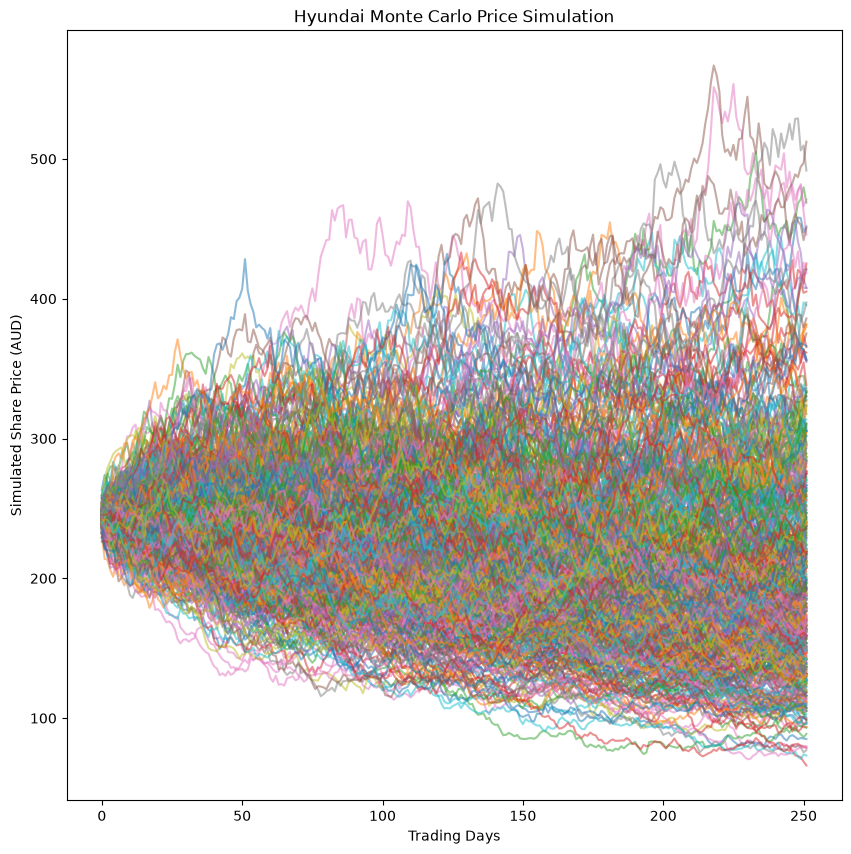

In [76]:
plt.figure(figsize=(10,10))
plt.plot(df2[:],alpha=0.5)
plt.xlabel('Trading Days')
plt.ylabel('Simulated Share Price (AUD)')
plt.title('Hyundai Monte Carlo Price Simulation')

In [87]:
df2

,0,1,2,3,4,5,6,7,8,9,...,490,491,492,493,494,495,496,497,498,499
0,263.547939,242.774047,241.785139,238.610452,241.968403,231.693475,239.832910,248.504036,247.320354,238.591694,...,250.602131,238.731408,240.757761,245.440792,255.276273,236.622057,243.890039,244.252486,239.878084,240.230257
1,273.878957,241.147869,241.555840,249.710475,238.523798,234.991938,247.960549,244.880526,238.762849,247.054647,...,251.529272,236.526258,248.395670,245.319756,260.277489,238.373444,235.716054,254.622601,242.416779,235.814808
2,268.693697,246.389681,234.283509,246.912375,244.432612,233.713068,246.533961,247.782900,247.698853,245.491598,...,247.995269,233.138105,243.585629,245.833566,264.993284,244.251139,227.199545,253.024753,241.533259,240.832776
3,265.755783,246.875721,231.139607,233.579082,248.900469,240.478591,238.445988,251.905817,246.979766,236.333672,...,247.862659,233.938334,243.498633,248.647863,265.269686,239.439720,235.986256,252.581091,238.922480,239.550850
4,259.468615,241.749034,230.952913,231.034456,248.039313,241.123668,239.146579,246.097932,254.600054,235.494482,...,252.790346,232.663795,239.871695,240.978843,259.607218,228.831800,239.900318,246.523153,231.991563,232.866212
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,120.528980,118.427762,186.734084,252.262823,154.959932,363.673848,93.850035,306.258690,209.999982,147.914761,...,221.293954,132.006834,189.803611,229.358167,270.475016,113.777465,422.562454,361.057584,138.277068,96.848692
248,122.058951,116.133722,186.909974,259.369555,152.856795,369.311043,96.797838,306.924903,210.455073,147.828450,...,218.626817,133.482134,196.147556,216.509283,259.598484,116.802383,433.760997,369.292461,132.482923,97.360100
249,121.020764,114.171776,178.117370,256.684393,151.547941,365.104793,94.689437,302.273166,206.858550,153.233149,...,219.488557,132.155821,191.794457,216.912939,253.535558,116.470433,414.798169,384.297331,132.225312,96.945751
250,119.941327,113.430894,171.915819,254.581810,151.730846,368.222275,93.439901,294.001974,199.392551,155.959687,...,208.652330,128.123482,190.253131,220.084353,252.801406,116.218677,425.848597,388.908037,126.865514,94.834677


In [ ]:
tdata=pd.read_csv('Hyundai_Share_Price.csv')
tdata.dtypes
df2.dtypes

0      float64
1      float64
2      float64
3      float64
4      float64
        ...   
495    float64
496    float64
497    float64
498    float64
499    float64
Length: 500, dtype: object

In [ ]:
tdata

,Date,Price (Korean Won),Price (Australian $)
0,8/25/26,"₩421,000.00",463.10
1,8/24/26,"₩414,000.00",455.40
2,8/21/26,"₩415,000.00",456.50
3,8/20/26,"₩417,500.00",459.25
4,8/19/26,"₩414,000.00",455.40
...,...,...,...
2087,2/1/19,"₩129,500.00",142.45
2088,1/31/19,"₩129,500.00",142.45
2089,1/30/19,"₩129,500.00",142.45
2090,1/29/19,"₩128,000.00",140.80


In [98]:
df2.iloc[:]

,0,1,2,3,4,5,6,7,8,9,...,490,491,492,493,494,495,496,497,498,499
0,263.547939,242.774047,241.785139,238.610452,241.968403,231.693475,239.832910,248.504036,247.320354,238.591694,...,250.602131,238.731408,240.757761,245.440792,255.276273,236.622057,243.890039,244.252486,239.878084,240.230257
1,273.878957,241.147869,241.555840,249.710475,238.523798,234.991938,247.960549,244.880526,238.762849,247.054647,...,251.529272,236.526258,248.395670,245.319756,260.277489,238.373444,235.716054,254.622601,242.416779,235.814808
2,268.693697,246.389681,234.283509,246.912375,244.432612,233.713068,246.533961,247.782900,247.698853,245.491598,...,247.995269,233.138105,243.585629,245.833566,264.993284,244.251139,227.199545,253.024753,241.533259,240.832776
3,265.755783,246.875721,231.139607,233.579082,248.900469,240.478591,238.445988,251.905817,246.979766,236.333672,...,247.862659,233.938334,243.498633,248.647863,265.269686,239.439720,235.986256,252.581091,238.922480,239.550850
4,259.468615,241.749034,230.952913,231.034456,248.039313,241.123668,239.146579,246.097932,254.600054,235.494482,...,252.790346,232.663795,239.871695,240.978843,259.607218,228.831800,239.900318,246.523153,231.991563,232.866212
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,120.528980,118.427762,186.734084,252.262823,154.959932,363.673848,93.850035,306.258690,209.999982,147.914761,...,221.293954,132.006834,189.803611,229.358167,270.475016,113.777465,422.562454,361.057584,138.277068,96.848692
248,122.058951,116.133722,186.909974,259.369555,152.856795,369.311043,96.797838,306.924903,210.455073,147.828450,...,218.626817,133.482134,196.147556,216.509283,259.598484,116.802383,433.760997,369.292461,132.482923,97.360100
249,121.020764,114.171776,178.117370,256.684393,151.547941,365.104793,94.689437,302.273166,206.858550,153.233149,...,219.488557,132.155821,191.794457,216.912939,253.535558,116.470433,414.798169,384.297331,132.225312,96.945751
250,119.941327,113.430894,171.915819,254.581810,151.730846,368.222275,93.439901,294.001974,199.392551,155.959687,...,208.652330,128.123482,190.253131,220.084353,252.801406,116.218677,425.848597,388.908037,126.865514,94.834677


In [109]:
# Historical variance (AUD)
true_var = tdata['Price (Australian $)'].var() 
mc_vars = df2.var(axis=0)
mc_var = mc_vars.mean()
error_pct = abs(mc_var - true_var) / true_var * 100

print(f"True variance: {true_var:.4f}")
print(f"Monte Carlo-Generated variance: {mc_var:.4f}")
print(f"Percentage error: {error_pct:.2f}%")


True variance: 11827.8870
Monte Carlo-Generated variance: 1307.9007
Percentage error: 88.94%
